# plot_AOD — CESM2 MA-GAUSS stratospheric-AOD uncertainty partition

Python port merging `plot_AOD.m` (global stratospheric-AOD time series and
uncertainty partition) with `plot_AOD_regions.m` (per-IPCC-continental-region
partition, which saves `AODVIS.mat`).

**Note:** `plot_AOD.m` references `tab_zm`/`tab_gm` (a baseline) that are never
defined in the script itself — a latent bug; AOD is an absolute field with no
baseline subtraction, and none of the AOD outputs use those variables, so the
undefined lines are omitted (documented here). `AODVIS` is *created in this
folder* → written to `data_py/AODVIS.npz`.

In [1]:
import sys, os, glob
import os as _os
_r = _os.getcwd()
while not _os.path.isdir(_os.path.join(_r, "python")) and _os.path.dirname(_r) != _r:
    _r = _os.path.dirname(_r)
_os.chdir(_r)   # notebooks live in j_notebooks/; anchor to project root
sys.path.insert(0, "python")
import numpy as np
import matplotlib.pyplot as plt
import mat_utils as mu
from mat_utils import brewermap, movmean, shaperead, inpolygon

fold = "/Volumes/D_Visioni2/CESM2_MA/MA_GAUSS/"
nam = "b.e21.BWSSP245.f09_g17.release-cesm2.1.3.WACCM-MA-1deg."
exp = ["feedback_30N_30S", "feedback_15N_15S", "feedback_0N_1.0", "feedback_60N_60S_1.0",
       "SSP245-MA-GAUSS-DEFAULT", "SSP245-MA-GAUSS-LOWER-0.5", "SSP245-MA-GAUSS-LOWER-1.0"]
exp2 = ["1.0 above PI - 30-30", "1.0 above PI - 15-15", "1.0 above PI - EQ",
        "1.0 above PI - 60-60", "1.5 above PI - MS", "1.0 above PI - MS", "0.5 above PI - MS"]
ids = ".cam.h0."
var = "AODVISstdn"
ens = ["001", "002", "003"]
nums = [3, 3, 3, 3, 3, 3, 3]

## Read MA-GAUSS AODVISstdn ensemble

In [2]:
ta = None
for ix, ex in enumerate(exp):
    for ie, en in enumerate(ens):
        f = sorted(glob.glob(f"{fold}{nam}{ex}.{en}{ids}{var}*.nc"))[0]
        t = mu.ncread(f, var)[:, :, 0:420].astype(np.float32)
        if ta is None:
            ta = np.empty(t.shape + (7, 3), dtype=np.float32)
        ta[:, :, :, ix, ie] = t
lat = mu.ncread(f, "lat").ravel(); lon = mu.ncread(f, "lon").ravel()

## Global mean stratospheric AOD and uncertainty partition

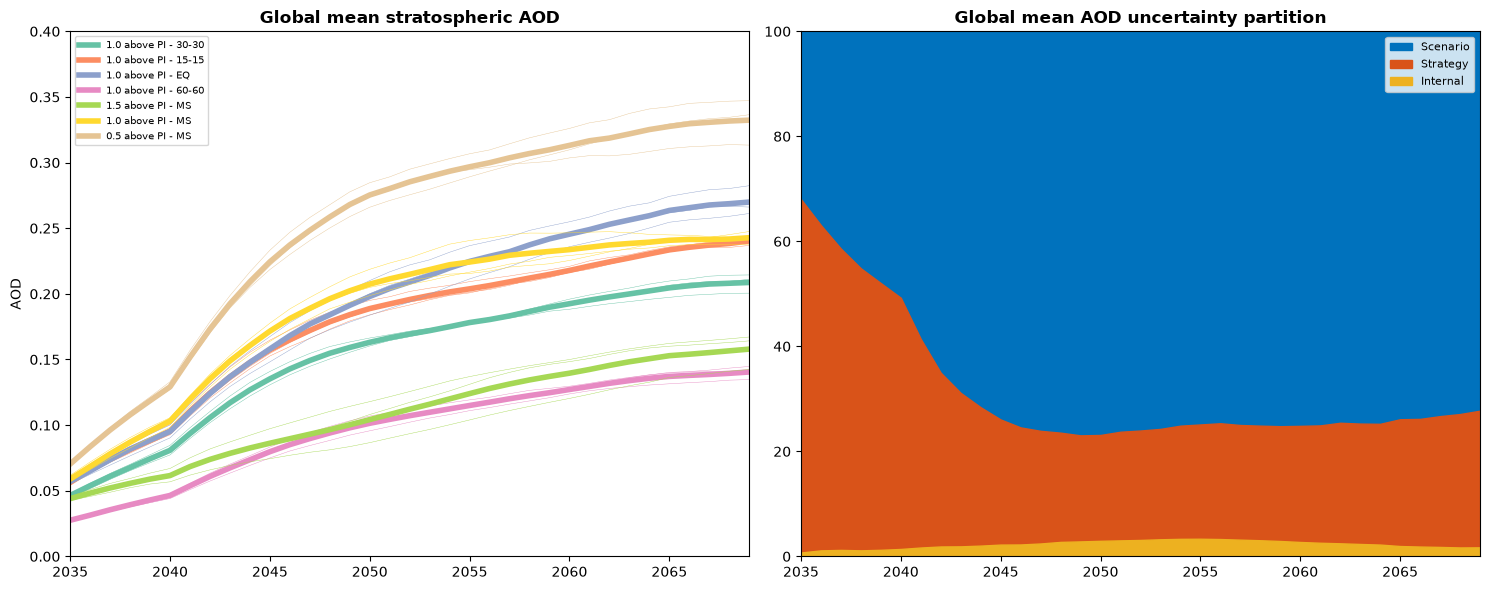

In [3]:
ww = np.cos(lat / 180 * np.pi)
ta_zm = np.nanmean(ta, axis=0)
ta_gm = (ta_zm * ww[:, None, None, None]).sum(0) / ww.sum()       # (420,7,3)
ta_gm_y = np.reshape(ta_gm, (12, 35, 7, 3), order="F").mean(0)    # (35,7,3)


def partition(y):
    iv = np.std(y[:, 4, :], axis=1, ddof=1) ** 2
    sv = np.std(y[:, [0, 1, 2, 3, 5], 0], axis=1, ddof=1) ** 2
    cv = np.std(y[:, 4:7, 0], axis=1, ddof=1) ** 2
    return iv, sv, cv


fc = brewermap(7, "Set2")
AREA_C = [(0, 0.4470, 0.7410), (0.8500, 0.3250, 0.0980), (0.9290, 0.6940, 0.1250)]
time = np.arange(2035, 2070)

fig1, (axa, axb) = plt.subplots(1, 2, figsize=(15, 6))
for ix in range(7):
    for ie in range(nums[ix]):
        axa.plot(time, movmean(ta_gm_y[:, ix, ie], 10), color=fc[ix], linewidth=.3)
    axa.plot(time, np.mean(movmean(ta_gm_y[:, ix, :], 10), axis=1), color=fc[ix],
             linewidth=4, label=exp2[ix])
axa.set_title("Global mean stratospheric AOD", fontweight="bold")
axa.set_xlim(2035, 2069); axa.set_ylim(0, 0.4); axa.set_ylabel("AOD")
axa.legend(fontsize=7, loc="upper left")

ta_gm_int_var, ta_gm_stra_var, ta_gm_sce_var = partition(ta_gm_y)
tot_var = ta_gm_int_var + ta_gm_stra_var + ta_gm_sce_var
axb.fill_between(time, movmean((ta_gm_stra_var + ta_gm_int_var + ta_gm_sce_var) / tot_var * 100, 10), 0,
                 color=AREA_C[0], label="Scenario")
axb.fill_between(time, movmean((ta_gm_stra_var + ta_gm_int_var) / tot_var * 100, 10), 0,
                 color=AREA_C[1], label="Strategy")
axb.fill_between(time, movmean(ta_gm_int_var / tot_var * 100, 10), 0, color=AREA_C[2], label="Internal")
axb.set_xlim(2035, 2069); axb.set_ylim(0, 100); axb.legend(fontsize=8)
axb.set_title("Global mean AOD uncertainty partition", fontweight="bold")
fig1.tight_layout(); plt.show()

## Per-IPCC-continental-region partition (merged from plot_AOD_regions) + save AODVIS

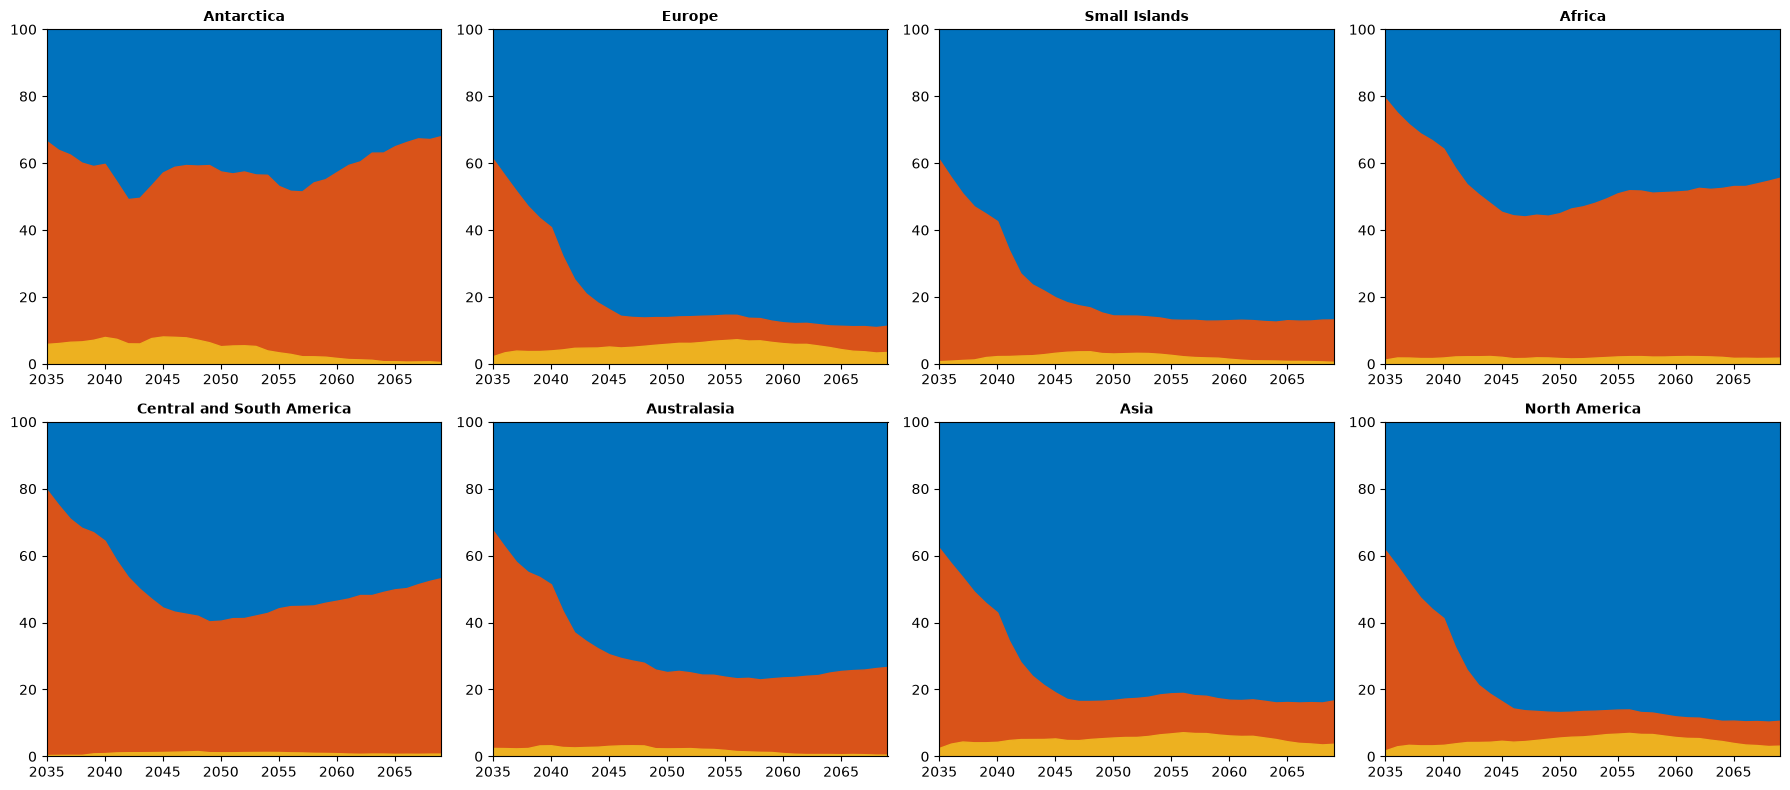

saved data_py/AODVIS.npz


In [4]:
regions = shaperead("IPCC_WGII_continental_regions.shx")
latM, lonM = np.meshgrid(lat, lon - 180)

ta_reg_int_var_all = np.full((35, 8), np.nan)
ta_reg_stra_var_all = np.full((35, 8), np.nan)
ta_reg_sce_var_all = np.full((35, 8), np.nan)
ta_reg_tot_var_all = np.full((35, 8), np.nan)

fig2, axes = plt.subplots(2, 4, figsize=(18, 8))
for fidx in range(8):
    ind = inpolygon(latM, lonM, regions[fidx].Y, regions[fidx].X)
    ta_reg_f = np.nanmean(ta[ind], axis=0)                       # (420,7,3)
    ta_reg_yf = np.reshape(ta_reg_f, (12, 35, 7, 3), order="F").mean(0)
    iv, sv, cv = partition(ta_reg_yf)
    tot = iv + sv + cv
    ta_reg_int_var_all[:, fidx] = iv
    ta_reg_stra_var_all[:, fidx] = sv
    ta_reg_sce_var_all[:, fidx] = cv
    ta_reg_tot_var_all[:, fidx] = np.std(np.reshape(movmean(ta_reg_yf, 10), (35, 21), order="F"),
                                         axis=1, ddof=1) ** 2
    ax = axes.ravel()[fidx]
    ax.fill_between(time, movmean((sv + iv + cv) / tot * 100, 10), 0, color=AREA_C[0])
    ax.fill_between(time, movmean((sv + iv) / tot * 100, 10), 0, color=AREA_C[1])
    ax.fill_between(time, movmean(iv / tot * 100, 10), 0, color=AREA_C[2])
    ax.set_xlim(2035, 2069); ax.set_ylim(0, 100)
    ax.set_title(regions[fidx].Region, fontweight="bold", fontsize=10)
fig2.tight_layout(); plt.show()

mu.save_npz("AODVIS",
            ta_reg_int_var_all=ta_reg_int_var_all, ta_reg_sce_var_all=ta_reg_sce_var_all,
            ta_reg_stra_var_all=ta_reg_stra_var_all, ta_reg_tot_var_all=ta_reg_tot_var_all,
            tot_var=tot_var, ta_gm_int_var=ta_gm_int_var,
            ta_gm_stra_var=ta_gm_stra_var, ta_gm_sce_var=ta_gm_sce_var)
print("saved data_py/AODVIS.npz")

In [5]:
os.makedirs("py_outputs", exist_ok=True)
fig1.savefig("py_outputs/HS_plot_map_AOD.png", dpi=300, bbox_inches="tight")
fig2.savefig("py_outputs/HS_plot_AODVIS_regions.png", dpi=300, bbox_inches="tight")
print("done")

done
